In [6]:
! pip install matplotlib 

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---- ----------------------------------- 0.


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import tensorflow as tf
import matplotlib.pyplot as plt
# import pandas as pd
# import seaborn as sns

In [10]:
import os
print("Current Working Directory: ", os.getcwd())

Current Working Directory:  c:\Users\danny\Documents\AICW SSCE\plant_leaf_disease_detection\archive


In [20]:
current_directory = os.getcwd()
train_path = os.path.join(current_directory, "data","Training")
valid_path = os.path.join(current_directory, "data","Validation")
test_path = os.path.join(current_directory, "data","Testing")

In [21]:
train_path

'c:\\Users\\danny\\Documents\\AICW SSCE\\plant_leaf_disease_detection\\archive\\data\\Training'

In [22]:
test_path

'c:\\Users\\danny\\Documents\\AICW SSCE\\plant_leaf_disease_detection\\archive\\data\\Testing'

In [23]:
valid_path

'c:\\Users\\danny\\Documents\\AICW SSCE\\plant_leaf_disease_detection\\archive\\data\\Validation'

In [25]:
#function is used to create an image dataset from the directory of images. It takes in the path to the directory, the image size, and the batch size as arguments. It returns a tf.data.Dataset object that can be used to train a model.
training_set = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    interpolation="bilinear",
)


Found 3251 files belonging to 3 classes.


In [34]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    interpolation="bilinear",
)

Found 416 files belonging to 3 classes.


In [35]:
cnn = tf.keras.models.Sequential()

cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Dropout(0.25))

cnn.add(tf.keras.layers.Flatten())
cnn.add(tf.keras.layers.Dense(units=1500,activation='relu'))
cnn.add(tf.keras.layers.Dropout(0.4))

cnn.add(tf.keras.layers.Dense(units=3,activation='softmax'))

c:\Users\danny\Documents\AICW SSCE\plant_leaf_disease_detection\archive\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [36]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

In [37]:
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1500)           │     3,073,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         4,503 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,790,227 (29.72 MB)

 Trainable params: 7,790,227 (29.72 MB)

 Non-trainable params: 0 (0.00 B)

In [44]:
training_history = cnn.fit(x=training_set, validation_data=validation_set, epochs=10)

Epoch 1/10


c:\Users\danny\Documents\AICW SSCE\plant_leaf_disease_detection\archive\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 548ms/step - accuracy: 0.4880 - loss: 0.9830 - val_accuracy: 0.5529 - val_loss: 0.9475
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 543ms/step - accuracy: 0.5361 - loss: 0.9557 - val_accuracy: 0.5072 - val_loss: 0.9346
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 528ms/step - accuracy: 0.5168 - loss: 0.9336 - val_accuracy: 0.5793 - val_loss: 0.9101
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - accuracy: 0.5264 - loss: 0.9620 - val_accuracy: 0.5577 - val_loss: 0.9387
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 537ms/step - accuracy: 0.5264 - loss: 0.9814 - val_accuracy: 0.5577 - val_loss: 0.9542
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - accuracy: 0.5601 - loss: 0.9206 - val_accuracy: 0.6202 - val_loss: 0.8807
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 554ms/step - accuracy: 0.5745 - loss: 0.8955 - val_accuracy: 0.6034 - val_loss: 0.8407
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 562ms/step - accuracy: 0.5889 - loss: 0.8793 - val_accuracy: 0.5865 - val_

In [45]:
val_loss, val_acc = cnn.evaluate(validation_set)
print('Validation accuracy:', val_acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 127ms/step - accuracy: 0.6250 - loss: 0.8337
Validation accuracy: 0.625


In [46]:
cnn.save('trained_plant_disease_model.keras')

In [47]:
training_history.history

{'accuracy': [0.48798078298568726,
  0.536057710647583,
  0.5168269276618958,
  0.526442289352417,
  0.526442289352417,
  0.5600961446762085,
  0.5745192170143127,
  0.588942289352417,
  0.6081730723381042,
  0.5288461446762085],
 'loss': [0.9829698801040649,
  0.955668568611145,
  0.9335664510726929,
  0.9620257616043091,
  0.9813766479492188,
  0.9206065535545349,
  0.8955286741256714,
  0.879326581954956,
  0.8471471071243286,
  0.9142907857894897],
 'val_accuracy': [0.5528846383094788,
  0.5072115659713745,
  0.5793269276618958,
  0.557692289352417,
  0.557692289352417,
  0.620192289352417,
  0.6033653616905212,
  0.5865384340286255,
  0.5913461446762085,
  0.625],
 'val_loss': [0.9475489854812622,
  0.9346310496330261,
  0.910075843334198,
  0.9387282729148865,
  0.9541504383087158,
  0.8806771039962769,
  0.8407334685325623,
  0.8624359369277954,
  0.9112497568130493,
  0.833689272403717]}

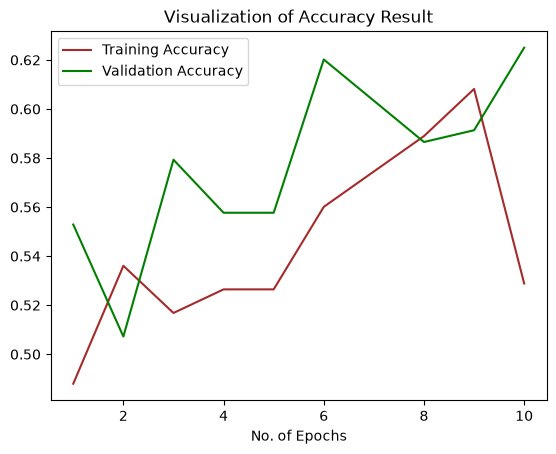

In [49]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='brown',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='green',label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show()